# Data Quality Pipeline — Results Analysis

This notebook loads the output files produced by the pipeline and generates
all required visuals and tables for the project report.

**Prerequisites:** Run the pipeline first:
```bash
python inject_errors.py --rows 100000
python validate_pipeline.py --input data/generated/corrupted --injection-meta data/generated/injection_metadata.json
python src/model_simulation.py
```

In [1]:
import json
import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Ensure output/report dirs exist
Path("data/reports").mkdir(parents=True, exist_ok=True)
Path("output").mkdir(parents=True, exist_ok=True)

plt.rcParams.update({
    "figure.figsize": (10, 6),
    "font.size": 12,
    "axes.grid": True,
    "grid.alpha": 0.3,
})
print("Setup complete.")

Setup complete.


## 1. Injected Rates and PyDeequ Outcomes

In [2]:
# Load injection metadata
with open("data/generated/injection_metadata.json") as f:
    injection_meta = json.load(f)

# Load validation results
with open("output/validation_results.json") as f:
    validation_results = json.load(f)

# Injection summary table
injection_df = pd.DataFrame([
    {"Fault Type": "NULL injection (feature_1)",
     "Target Rate": f"{injection_meta['null_injection_rate']*100:.1f}%",
     "Actual Rate": f"{injection_meta['null_injection_actual_rate']*100:.2f}%",
     "Affected Rows": injection_meta['null_injection_actual_count']},
    {"Fault Type": "Scale shift (feature_2 × 1000)",
     "Target Rate": f"{injection_meta['unit_shift_rate']*100:.1f}%",
     "Actual Rate": f"{injection_meta['unit_shift_actual_rate']*100:.2f}%",
     "Affected Rows": injection_meta['unit_shift_actual_count']},
    {"Fault Type": "Duplicate rows",
     "Target Rate": f"{injection_meta['duplicate_rate']*100:.1f}%",
     "Actual Rate": f"{injection_meta['duplicate_actual_rate']*100:.2f}%",
     "Affected Rows": injection_meta['duplicate_actual_count']},
])
print("=== Fault Injection Summary ===")
print(f"Input rows:  {injection_meta['input_row_count']:,}")
print(f"Output rows: {injection_meta['output_row_count']:,}")
print(f"Duplicate IDs: {injection_meta['duplicate_id_count']:,}")
print()
display(injection_df)
injection_df.to_csv("data/reports/injection_summary.csv", index=False)

=== Fault Injection Summary ===
Input rows:  10,000
Output rows: 10,300
Duplicate IDs: 300



,Fault Type,Target Rate,Actual Rate,Affected Rows
0,NULL injection (feature_1),5.0%,4.75%,475
1,Scale shift (feature_2 × 1000),2.0%,1.75%,175
2,Duplicate rows,3.0%,3.00%,300


In [3]:
# PyDeequ validation outcomes
checks_df = pd.DataFrame(validation_results["checks"])
print(f"=== Validation Results (passed={validation_results['passed']}) ===")
print(f"Row count: {validation_results['row_count']:,}")
print(f"Fault categories detected: {validation_results['fault_categories_detected']}")
print(f"Runtime: {validation_results['runtime_seconds']:.2f}s")
print()
display(checks_df[["name", "status", "observed", "expected", "failure_reason"]])
checks_df.to_csv("data/reports/validation_checks.csv", index=False)

=== Validation Results (passed=False) ===
Row count: 10,300
Fault categories detected: ['duplicate_ids', 'missing_values', 'out_of_range_values', 'unit_scale_shift']
Runtime: 9.57s



,name,status,observed,expected,failure_reason
0,feature_1_completeness,FAILED,0.952816,1.0,Null rate exceeds threshold (expected >= 1.0)
1,feature_2_completeness,PASSED,1.000000,1.0,NaN
2,id_completeness,PASSED,1.000000,1.0,NaN
3,target_completeness,PASSED,1.000000,1.0,NaN
4,id_uniqueness,FAILED,0.941748,1.0,Duplicate IDs found (uniqueness < 1.0)
5,feature_3_required,PASSED,1.000000,1.0,NaN
6,subgroup_required,PASSED,1.000000,1.0,NaN
7,batch_id_required,PASSED,1.000000,1.0,NaN
8,feature_1_min,PASSED,-33.130892,-100.0,NaN
9,feature_1_max,PASSED,35.688349,100.0,NaN


## 2. Accuracy Comparison: Clean vs Corrupted vs Validated

In [4]:
# Load accuracy results
acc_df = pd.read_csv("output/accuracy_comparison.csv")
display(acc_df)

with open("output/runtime_metrics.json") as f:
    runtime_metrics = json.load(f)

print("\n=== Accuracy Deltas (clean → corrupted) ===")
deltas = runtime_metrics["accuracy_deltas"]
print(f"  Overall drop:    {deltas['overall_drop_pp']:.2f} pp")
print(f"  Subgroup A drop: {deltas['subgroup_A_drop_pp']:.2f} pp")
print(f"  Subgroup B drop: {deltas['subgroup_B_drop_pp']:.2f} pp")
print(f"  B degrades more than A: {deltas['B_degrades_more_than_A']}")
print(f"\nValidated state policy: {runtime_metrics['validated_state_policy']}")

,state,overall_accuracy,subgroup_A_accuracy,subgroup_B_accuracy,row_count,subgroup_A_count,subgroup_B_count,policy
0,clean_baseline,0.853000,0.804305,0.903885,10000,5000,5000,NaN
1,corrupted_no_checks,0.809709,0.810828,0.808606,10300,5156,5144,NaN
2,validated_quarantined,0.848000,0.801609,0.893899,10000,5000,5000,Quarantine rejected bad batch; fell back to cl...



=== Accuracy Deltas (clean → corrupted) ===
  Overall drop:    4.33 pp
  Subgroup A drop: -0.65 pp
  Subgroup B drop: 9.53 pp
  B degrades more than A: True

Validated state policy: Quarantine policy: bad batch rejected by PyDeequ validation. Inference falls back to the clean baseline dataset. Accuracy is near-identical to clean baseline with minor variance from a different train/test split (operational simulation).


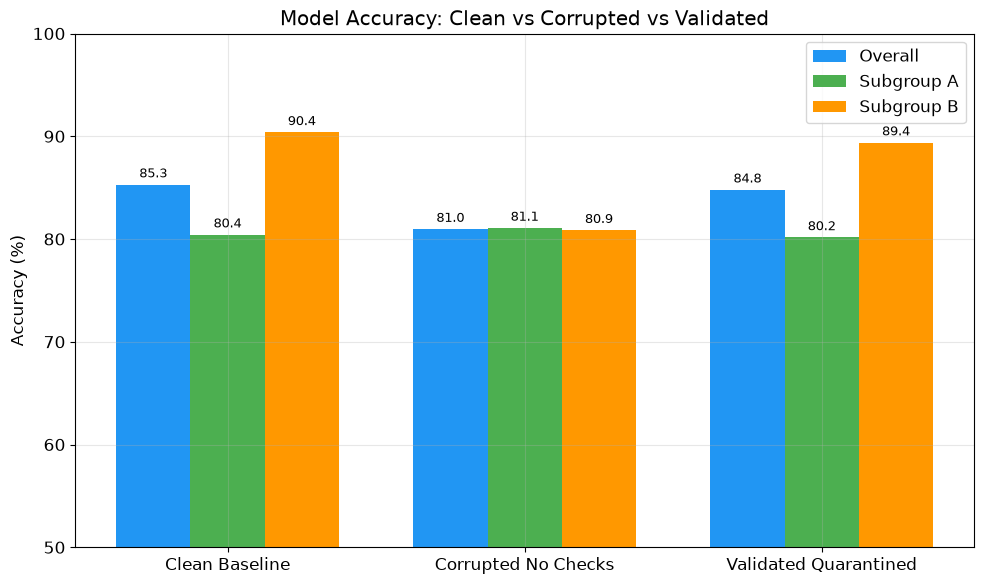

Saved: data/reports/accuracy_comparison.png


In [5]:
# === Figure 1: Grouped accuracy bar chart ===
states = acc_df["state"].tolist()
x = np.arange(len(states))
width = 0.25

fig, ax = plt.subplots(figsize=(10, 6))
bars1 = ax.bar(x - width, acc_df["overall_accuracy"] * 100, width, label="Overall", color="#2196F3")
bars2 = ax.bar(x, acc_df["subgroup_A_accuracy"] * 100, width, label="Subgroup A", color="#4CAF50")
bars3 = ax.bar(x + width, acc_df["subgroup_B_accuracy"] * 100, width, label="Subgroup B", color="#FF9800")

ax.set_ylabel("Accuracy (%)")
ax.set_title("Model Accuracy: Clean vs Corrupted vs Validated")
ax.set_xticks(x)
ax.set_xticklabels([s.replace("_", " ").title() for s in states])
ax.legend()
ax.set_ylim(50, 100)

# Add value labels
for bars in [bars1, bars2, bars3]:
    for bar in bars:
        h = bar.get_height()
        ax.annotate(f"{h:.1f}", xy=(bar.get_x() + bar.get_width()/2, h),
                    xytext=(0, 3), textcoords="offset points", ha="center", va="bottom", fontsize=9)

plt.tight_layout()
plt.savefig("data/reports/accuracy_comparison.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved: data/reports/accuracy_comparison.png")

## 3. Accuracy Changes and Subgroup Disparity

In [6]:
# Accuracy change table
clean = acc_df[acc_df["state"] == "clean_baseline"].iloc[0]
corrupted = acc_df[acc_df["state"] == "corrupted_no_checks"].iloc[0]
validated = acc_df[acc_df["state"] == "validated_quarantined"].iloc[0]

change_df = pd.DataFrame([
    {"Metric": "Overall",
     "Clean": f"{clean['overall_accuracy']*100:.2f}%",
     "Corrupted": f"{corrupted['overall_accuracy']*100:.2f}%",
     "Validated": f"{validated['overall_accuracy']*100:.2f}%",
     "Drop (pp)": f"{(clean['overall_accuracy'] - corrupted['overall_accuracy'])*100:.2f}",
     "Recovery (pp)": f"{(validated['overall_accuracy'] - corrupted['overall_accuracy'])*100:.2f}"},
    {"Metric": "Subgroup A",
     "Clean": f"{clean['subgroup_A_accuracy']*100:.2f}%",
     "Corrupted": f"{corrupted['subgroup_A_accuracy']*100:.2f}%",
     "Validated": f"{validated['subgroup_A_accuracy']*100:.2f}%",
     "Drop (pp)": f"{(clean['subgroup_A_accuracy'] - corrupted['subgroup_A_accuracy'])*100:.2f}",
     "Recovery (pp)": f"{(validated['subgroup_A_accuracy'] - corrupted['subgroup_A_accuracy'])*100:.2f}"},
    {"Metric": "Subgroup B",
     "Clean": f"{clean['subgroup_B_accuracy']*100:.2f}%",
     "Corrupted": f"{corrupted['subgroup_B_accuracy']*100:.2f}%",
     "Validated": f"{validated['subgroup_B_accuracy']*100:.2f}%",
     "Drop (pp)": f"{(clean['subgroup_B_accuracy'] - corrupted['subgroup_B_accuracy'])*100:.2f}",
     "Recovery (pp)": f"{(validated['subgroup_B_accuracy'] - corrupted['subgroup_B_accuracy'])*100:.2f}"},
])
display(change_df)
change_df.to_csv("data/reports/accuracy_changes.csv", index=False)

print("\n=== Subgroup Disparity ===")
disparity_clean = abs(clean["subgroup_A_accuracy"] - clean["subgroup_B_accuracy"])
disparity_corr = abs(corrupted["subgroup_A_accuracy"] - corrupted["subgroup_B_accuracy"])
print(f"  Clean A-B gap:     {disparity_clean*100:.2f} pp")
print(f"  Corrupted A-B gap: {disparity_corr*100:.2f} pp")
print(f"  Disparity increase: {(disparity_corr - disparity_clean)*100:.2f} pp")

,Metric,Clean,Corrupted,Validated,Drop (pp),Recovery (pp)
0,Overall,85.30%,80.97%,84.80%,4.33,3.83
1,Subgroup A,80.43%,81.08%,80.16%,-0.65,-0.92
2,Subgroup B,90.39%,80.86%,89.39%,9.53,8.53



=== Subgroup Disparity ===
  Clean A-B gap:     9.96 pp
  Corrupted A-B gap: 0.22 pp
  Disparity increase: -9.74 pp


## 4. Feature 2 Distribution: Before vs After Corruption

2026-11-04 19:30:59,636 [INFO] Found cached Deequ JAR: C:\Users\warri\.ivy2.5.2\cache\com.amazon.deequ\deequ\jars\deequ-2.0.18-spark-4.1.jar


D:\Prithvi\Academics\College\Sem5\BDSRAE\DataQualityProject\venv\Lib\site-packages\pyspark\testing\utils.py:127: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


D:\Prithvi\Academics\College\Sem5\BDSRAE\DataQualityProject\venv\Lib\site-packages\pyspark\sql\pandas\conversion.py:324: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
D:\Prithvi\Academics\College\Sem5\BDSRAE\DataQualityProject\venv\Lib\site-packages\pyspark\sql\pandas\conversion.py:374: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


D:\Prithvi\Academics\College\Sem5\BDSRAE\DataQualityProject\venv\Lib\site-packages\pyspark\sql\pandas\conversion.py:324: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
D:\Prithvi\Academics\College\Sem5\BDSRAE\DataQualityProject\venv\Lib\site-packages\pyspark\sql\pandas\conversion.py:374: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


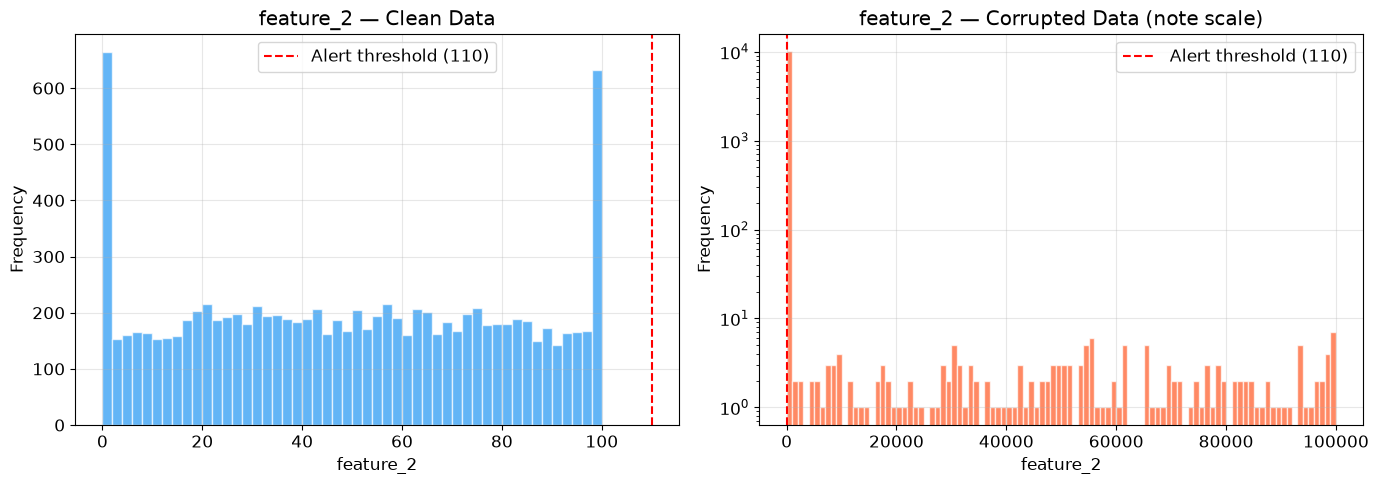

Saved: data/reports/feature2_distribution.png

Clean  feature_2: min=0.00  max=100.00  mean=49.74
Corrupted feature_2: min=0.00  max=100000.00  mean=965.20


In [7]:
os.environ["SPARK_VERSION"] = "4.1"
sys.path.insert(0, "src")
from data_generation import _build_spark

spark = _build_spark("NotebookAnalysis")

df_clean = spark.read.parquet("data/generated/clean").select("feature_2", "subgroup").toPandas()
df_corrupted = spark.read.parquet("data/generated/corrupted").select("feature_2", "subgroup").toPandas()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Clean distribution
axes[0].hist(df_clean["feature_2"], bins=50, alpha=0.7, color="#2196F3", edgecolor="white")
axes[0].set_title("feature_2 — Clean Data")
axes[0].set_xlabel("feature_2")
axes[0].set_ylabel("Frequency")
axes[0].axvline(x=110, color="red", linestyle="--", label="Alert threshold (110)")
axes[0].legend()

# Corrupted distribution (log scale to show the 1000x shifted values)
axes[1].hist(df_corrupted["feature_2"], bins=100, alpha=0.7, color="#FF5722", edgecolor="white")
axes[1].set_title("feature_2 — Corrupted Data (note scale)")
axes[1].set_xlabel("feature_2")
axes[1].set_ylabel("Frequency")
axes[1].set_yscale("log")
axes[1].axvline(x=110, color="red", linestyle="--", label="Alert threshold (110)")
axes[1].legend()

plt.tight_layout()
plt.savefig("data/reports/feature2_distribution.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved: data/reports/feature2_distribution.png")

# Stats comparison
print(f"\nClean  feature_2: min={df_clean['feature_2'].min():.2f}  max={df_clean['feature_2'].max():.2f}  mean={df_clean['feature_2'].mean():.2f}")
print(f"Corrupted feature_2: min={df_corrupted['feature_2'].min():.2f}  max={df_corrupted['feature_2'].max():.2f}  mean={df_corrupted['feature_2'].mean():.2f}")

## 5. Validation Overhead and Fault Detection

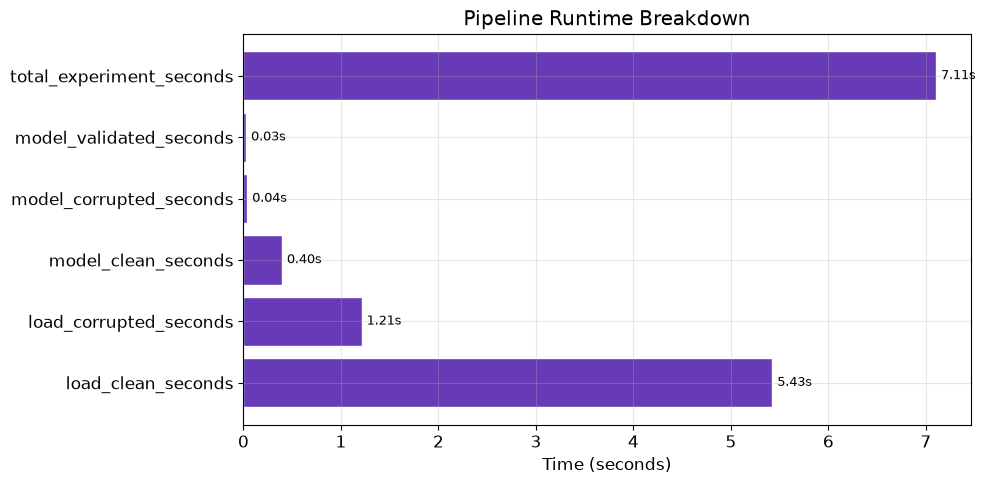

Saved: data/reports/runtime_breakdown.png

Validation runtime: 9.57s
Target validation overhead (100M rows): ~4.2 minutes
Measured validation overhead (10,300 rows): 9.57s


In [8]:
# Runtime chart
timings = runtime_metrics["timings"]
timing_labels = list(timings.keys())
timing_values = list(timings.values())

fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.barh(timing_labels, timing_values, color="#673AB7", edgecolor="white")
ax.set_xlabel("Time (seconds)")
ax.set_title("Pipeline Runtime Breakdown")
for bar, val in zip(bars, timing_values):
    ax.text(bar.get_width() + 0.05, bar.get_y() + bar.get_height()/2,
            f"{val:.2f}s", va="center", fontsize=9)
plt.tight_layout()
plt.savefig("data/reports/runtime_breakdown.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved: data/reports/runtime_breakdown.png")

print(f"\nValidation runtime: {validation_results['runtime_seconds']:.2f}s")
print(f"Target validation overhead (100M rows): ~4.2 minutes")
print(f"Measured validation overhead ({validation_results['row_count']:,} rows): {validation_results['runtime_seconds']:.2f}s")

In [9]:
# === Fault Detection Matrix ===
fault_types = ["missing_values", "unit_scale_shift", "duplicate_ids", "out_of_range_values"]
check_names = [c["name"] for c in validation_results["checks"]]
check_statuses = [c["status"] for c in validation_results["checks"]]

# Map checks to fault categories
detection_matrix = {}
for ft in fault_types:
    detection_matrix[ft] = {}
    for name, status in zip(check_names, check_statuses):
        relevant = False
        if ft == "missing_values" and ("completeness" in name or "required" in name):
            relevant = True
        elif ft == "duplicate_ids" and "uniqueness" in name:
            relevant = True
        elif ft == "unit_scale_shift" and ("scale_shift" in name or "feature_2_max" in name):
            relevant = True
        elif ft == "out_of_range_values" and ("min" in name or "max" in name):
            relevant = True
        if relevant:
            detection_matrix[ft][name] = status

# Build a heatmap-style table
all_checks_in_matrix = sorted(set(c for checks in detection_matrix.values() for c in checks))
matrix_data = []
for ft in fault_types:
    row = {"Fault Category": ft}
    for cn in all_checks_in_matrix:
        row[cn] = detection_matrix[ft].get(cn, "—")
    matrix_data.append(row)

matrix_df = pd.DataFrame(matrix_data).set_index("Fault Category")
display(matrix_df)
matrix_df.to_csv("data/reports/fault_detection_matrix.csv")

print(f"\nDetected categories: {validation_results['fault_categories_detected']}")

,batch_id_required,feature_1_completeness,feature_1_max,feature_1_min,feature_2_completeness,feature_2_max,feature_2_min,feature_2_scale_shift,feature_3_max,feature_3_min,feature_3_required,id_completeness,id_uniqueness,subgroup_required,target_completeness
Fault Category,,,,,,,,,,,,,,,
missing_values,PASSED,FAILED,—,—,PASSED,—,—,—,—,—,PASSED,PASSED,—,PASSED,PASSED
unit_scale_shift,—,—,—,—,—,FAILED,—,FAILED,—,—,—,—,—,—,—
duplicate_ids,—,—,—,—,—,—,—,—,—,—,—,—,FAILED,—,—
out_of_range_values,—,—,PASSED,PASSED,—,FAILED,PASSED,—,PASSED,PASSED,—,—,—,—,—



Detected categories: ['duplicate_ids', 'missing_values', 'out_of_range_values', 'unit_scale_shift']


## 6. Null and Duplicate Summary

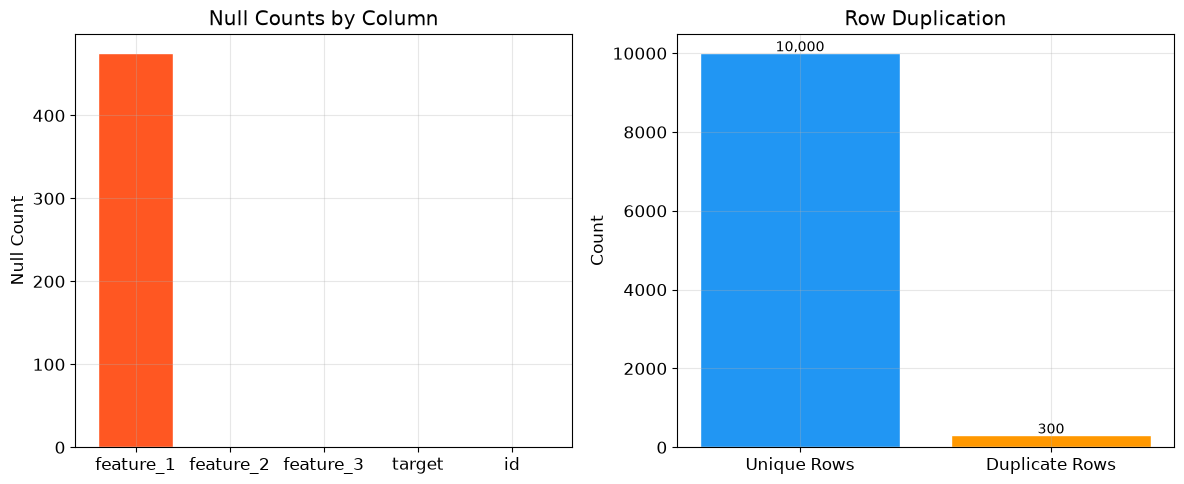

Saved: data/reports/null_duplicate_summary.png


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Null summary
null_data = {
    "feature_1": injection_meta["null_injection_actual_count"],
    "feature_2": 0,
    "feature_3": 0,
    "target": 0,
    "id": 0,
}
colors = ["#FF5722" if v > 0 else "#4CAF50" for v in null_data.values()]
axes[0].bar(null_data.keys(), null_data.values(), color=colors, edgecolor="white")
axes[0].set_title("Null Counts by Column")
axes[0].set_ylabel("Null Count")

# Duplicate summary
dup_labels = ["Unique Rows", "Duplicate Rows"]
dup_vals = [
    injection_meta["input_row_count"],
    injection_meta["duplicate_actual_count"],
]
axes[1].bar(dup_labels, dup_vals, color=["#2196F3", "#FF9800"], edgecolor="white")
axes[1].set_title("Row Duplication")
axes[1].set_ylabel("Count")
for i, v in enumerate(dup_vals):
    axes[1].text(i, v + 50, f"{v:,}", ha="center", fontsize=10)

plt.tight_layout()
plt.savefig("data/reports/null_duplicate_summary.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved: data/reports/null_duplicate_summary.png")

In [11]:
spark.stop()
print("Analysis complete. All figures and tables exported to data/reports/")

Analysis complete. All figures and tables exported to data/reports/
